# Text classification and error analysis

After this block you can train and evaluate a text classifier on high-dimensional TF-IDF features for a task with more than 1,000 classes, read its errors, recognise leakage through a text that exists only after the decision, compress the sparse matrix with truncated SVD, and explain what word counts cannot capture. You also make the first leaderboard submission (round L1) of the EBTI case study.

## Teaching map

| Section | Minutes | What it delivers |
|---|---|---|
| 1 · The EBTI task | 5 | the decision to support, allowed inputs, split by time, leaderboard rounds |
| 2 · Linear models for text classification | 8 | scores as weighted sums of n-grams; naive Bayes and a linear SVM in a pipeline |
| 3 · Metrics for more than 1,000 classes | 9 | accuracy and macro-F1, rare headings, top-k, time split against random split |
| 4 · Error analysis and the most informative n-grams | 8 | confusions of neighbouring headings, 20 errors read with keywords, coefficients, quoted codes |
| 5 · Leakage through the customs' justification | 5 | a column that makes validation look excellent and fails in use |
| 6 · Dimensionality reduction with truncated SVD | 4 | latent semantic analysis; what the first components capture |
| 7 · The limits of word counts | 3 | synonyms, languages, order, unknown words; the bridge to Session 14 |
| Worked example · leaderboard round L1 | 3 | refit, predict, check and score a submission |

**Core path for the 45-minute lecture:** the numbered sections without the subsections marked *(depth: self-study or if time allows)*, plus the worked example. The depth subsections benchmark eight classifiers, plot the average feature effects per class, and cluster descriptions with LSA and k-means; they are written for self-study after class.

```mermaid
flowchart LR
    T["Training decisions<br/>2017-2021"] --> V["TfidfVectorizer"]
    V --> C["Linear SVM<br/>(SGDClassifier, hinge)"]
    C --> E["Validation 2022-2023:<br/>accuracy, macro-F1,<br/>per-heading report"]
    E --> A["Error analysis:<br/>confusions, 20 errors,<br/>top n-grams"]
    A -->|"change features<br/>or data"| V
    E -->|"choose settings"| F["Refit on all<br/>sample decisions"]
    F --> S["Leaderboard L1"]
```

In [1]:
# Run the code from the repository root, where the case-study paths start.
import os
from pathlib import Path

os.chdir(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "case-study").is_dir()))

## 1 · The EBTI task: predicting the customs heading in 23 languages

**The decision to support.** Every product that crosses the EU border is classified in the customs tariff, and the classification decides the duty. A trader who is unsure can ask a customs authority for a **Binding Tariff Information** (BTI) decision: the trader describes the product, customs states its code, and the European Commission publishes all decisions in the EBTI database. Classifying takes an expert's time. A model that reads the description and proposes the most likely codes can save that time, provided we know how often it is right and where it fails.

**The codes.** The tariff follows the Harmonized System (HS): 21 sections, 97 chapters (two digits, for example 64 footwear), about 1,200 **headings** (four digits, for example 6404 footwear with textile uppers) and finer subheadings. Our label is the four-digit heading. Think of a library: the section is the floor, the chapter the shelf, the heading the exact place on the shelf.

**The data** (see [case-study/README.md](../../../case-study/README.md)):

| Table | Rows | What it contains |
|---|---|---|
| `train` | 309,529 decisions, 2017–2023 | description, language, issuing country, start date, the label `heading`, and columns customs wrote together with the decision (keywords, justification, full code) |
| `train_sample` | 50,000 | a random sample of `train`, used for all experiments in this block |
| `test` | 113,188 decisions, 2024–2026 | only what a request contains: `id`, issuing country, language, start date, description |
| `nomenclature` | 1,229 headings | the English text of every heading, chapter and section |

**The split is by time.** Models are trained on decisions up to 2023 and predict later ones, as they would in use. The **public leaderboard** scores 2024, the **private leaderboard** 2025–2026, which stays hidden. A submission is a CSV file with the columns `id,heading`, one row per test decision. There are three rounds: **L1** with a TF-IDF classifier (this block), **L2** with embeddings or a language model (Session 14), **L3** after retraining with the released 2024 labels (Session 16).

Next we load the sample, the test set and the nomenclature and check what the test set contains. `DataFrame.columns.tolist()` lists the columns; `.dt.year` extracts the year of a date.

In [2]:
import numpy as np
import pandas as pd

decisions = pd.read_parquet("case-study/data/train_sample.parquet")
test = pd.read_parquet("case-study/data/test.parquet")
nomenclature = pd.read_parquet("case-study/data/nomenclature.parquet").set_index("heading")
print(len(decisions), "sample decisions,", decisions["heading"].nunique(), "headings,",
      decisions["language"].nunique(), "languages")
print("test columns:", test.columns.tolist())
print("test decisions per year:", test["start_date"].dt.year.value_counts().sort_index().to_dict())

50000 sample decisions, 934 headings, 23 languages
test columns: ['id', 'issuing_country', 'language', 'start_date', 'description']
test decisions per year: {2024: 40369, 2025: 41126, 2026: 31693}


**Predict before running:** the most frequent heading is 3926 ("other articles of plastics"). What share of all decisions do you expect it to have: 4 %, 14 % or 40 %? And how many headings have fewer than ten decisions in the sample?

In [3]:
counts = decisions["heading"].value_counts()
top = counts.head(5).to_frame("n").assign(share=lambda d: (d["n"] / len(decisions)).round(3))
top["name"] = nomenclature["heading_description"].reindex(top.index).str[:45]
print(top)
print((counts < 10).sum(), "of", len(counts), "headings have fewer than 10 decisions")

            n  share                                           name
heading                                                            
3926     2009  0.040  Articles of plastics and articles of other ma
9503     1424  0.028  Tricycles, scooters, pedal cars and similar w
6307     1374  0.027  Textiles; made up articles n.e.c. in chapter 
2106     1364  0.027  Food preparations not elsewhere specified or 
4202     1269  0.025  Trunks; suit, camera, jewellery, cutlery case
444 of 934 headings have fewer than 10 decisions


The headings have a **long tail**: a few hundred frequent headings and many rare ones. This shapes everything that follows, from the choice of model to the choice of metric.

> **Note.** `keywords`, `classification_justification`, `cn_code`, `chapter`, `status` and the end dates are written by customs together with or after the decision. They are not in the test set and must not be model inputs. Section 5 measures what happens when this rule is broken. They may be used for *reading* decisions during error analysis.

**In practice.** Kaggle and Codabench competitions use the protocol of the course leaderboard: a hidden test set, a fixed submission format, a public leaderboard during the competition and a private one for the final ranking. Decisions can be looked up in the public EBTI database, so the leaderboard score is not graded.

## 2 · Linear models for text classification

A **linear classifier** computes one score per class as a weighted sum of the features plus an intercept, score_k(d) = b_k + Σ_j w_kj · x_dj, and predicts the class with the highest score. For text each feature is an n-gram, so each weight says how much that n-gram pushes a description towards a heading. It works like a points system: every word in the description adds or subtracts points for every heading, and the heading with most points wins.

By hand: the weights for heading 6404 (textile uppers) and the TF-IDF values of one description are

| n-gram | weight (6404) | value | product |
|---|---|---|---|
| textile | 2.0 | 0.5 | 1.0 |
| leather | −3.0 | 0.4 | −1.2 |
| textile upper | 4.0 | 0.6 | 2.4 |

With intercept −1.0 the score for 6404 is −1.0 + 1.0 − 1.2 + 2.4 = 1.2. The model computes such a score for every heading and picks the largest.

Three linear classifiers are common for text:

| Model | Idea | Output | Notes |
|---|---|---|---|
| multinomial or complement naive Bayes | word probabilities per class, assumed independent | probabilities (poorly calibrated) | very fast; works on counts |
| logistic regression | minimises log-loss; softmax turns scores into probabilities (Session 6) | probabilities | slow with 1,000 classes and 100,000 features |
| linear support vector machine | maximises the margin between classes | scores only | here trained with `SGDClassifier(loss="hinge")` |

With many classes scikit-learn trains one binary model per class ("one versus rest"). `SGDClassifier` fits them by **stochastic gradient descent**: it passes over the data `max_iter` times and updates the weights after each example, which is fast enough for 300,000 decisions and 1,100 headings. `alpha` is the strength of the regularisation penalty (larger means simpler models); `LogisticRegression` and `LinearSVC` use `C`, its inverse.

Linear models suit text because the data are sparse and high-dimensional: with tens of thousands of columns, most classes can be separated by a hyperplane, and the fitted weights belong to readable n-grams.

**Validation by time.** The leaderboard predicts later years from earlier ones, so we validate the same way: train on 2017–2021, validate on 2022–2023. Next we make the split with Boolean masks.

In [4]:
year = decisions["start_date"].dt.year
train, valid = decisions[year <= 2021], decisions[year >= 2022]
print(len(train), "training decisions,", len(valid), "validation decisions,",
      train["heading"].nunique(), "headings in training")

36801 training decisions, 13199 validation decisions, 890 headings in training


Next we put the vectoriser and the classifier into one pipeline with `make_pipeline`, so that `fit` learns vocabulary and idf from the training years only. `time.perf_counter()` measures the fitting time; `accuracy_score` and `f1_score(..., average="macro")` are explained in section 3.

In [5]:
import time

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import SGDClassifier
from sklearn.metrics import accuracy_score, f1_score
from sklearn.pipeline import make_pipeline


def svm():
    # A linear SVM fitted by stochastic gradient descent: fast with 1,000 classes.
    return SGDClassifier(loss="hinge", alpha=1e-5, max_iter=20, tol=None, random_state=0, n_jobs=-1)


def report(name, y_true, y_pred, t0=None):
    secs = f"  {time.perf_counter() - t0:4.0f} s" if t0 else ""
    print(f"{name:32s} accuracy {accuracy_score(y_true, y_pred):.3f}  "
          f"macro-F1 {f1_score(y_true, y_pred, average='macro'):.3f}{secs}")

In [6]:
t0 = time.perf_counter()
model = make_pipeline(TfidfVectorizer(min_df=2, sublinear_tf=True), svm())
model.fit(train["description"], train["heading"])
pred = model.predict(valid["description"])
report("linear SVM, word TF-IDF", valid["heading"], pred, t0)

linear SVM, word TF-IDF          accuracy 0.772  macro-F1 0.511     8 s


**Predict before running:** complement naive Bayes on word counts is one of the fastest text classifiers. Will it be better or worse than the linear SVM here? `ComplementNB` is a variant of naive Bayes designed for unbalanced classes.

In [7]:
from sklearn.naive_bayes import ComplementNB

t0 = time.perf_counter()
nb = make_pipeline(CountVectorizer(min_df=2), ComplementNB()).fit(train["description"], train["heading"])
report("complement naive Bayes, counts", valid["heading"], nb.predict(valid["description"]), t0)

complement naive Bayes, counts   accuracy 0.636  macro-F1 0.350     4 s


The case-study README gives reference values on the 2024 public leaderboard: word TF-IDF with a linear SVM reaches 0.806 accuracy on the 50,000-decision sample and 0.872 on the full training set, and character n-grams (3–5) on the full set reach 0.882 (case-study README, 2026). More data helps more than a cleverer representation.

> **Note.** Do not compare models on the leaderboard. Choose the analyzer, n-gram range, `min_df` and `alpha` on the validation years; use the leaderboard once per round, for the final choice.

**In practice.** Routing e-mails and support tickets to the right team is often done with TF-IDF and a linear model, because it is cheap to retrain when categories change. Joulin et al. (2017) showed with fastText that a linear classifier on word and character n-grams comes close to deep neural networks on standard text-classification benchmarks while training in seconds.

### Benchmarking classifiers on sparse text features (depth: self-study or if time allows)

*Adapted from [Classification of text documents using sparse features](https://scikit-learn.org/stable/auto_examples/text/plot_document_classification_20newsgroups.html) (scikit-learn developers, BSD-3-Clause), on EBTI data.*

scikit-learn offers many classifiers. Here we train eight of them on the same text task and measure both accuracy and speed, at training and at prediction time. To keep it fast we use a smaller task: the headings of four chapters, 39 (plastics), 64 (footwear), 85 (electrical machinery) and 95 (toys and games). The vectoriser drops words in more than half of the documents (`max_df=0.5`) and words in fewer than five (`min_df=5`).

In [8]:
chapters = ["39", "64", "85", "95"]
small_tr = train[train["chapter"].isin(chapters)]
small_va = valid[valid["chapter"].isin(chapters)]
vec_small = TfidfVectorizer(sublinear_tf=True, max_df=0.5, min_df=5)
X_train = vec_small.fit_transform(small_tr["description"])
X_test = vec_small.transform(small_va["description"])
y_train, y_test = small_tr["heading"], small_va["heading"]
print(f"{X_train.shape[0]:,} training and {X_test.shape[0]:,} validation decisions, "
      f"{X_train.shape[1]:,} features, {y_train.nunique()} headings")

11,130 training and 3,768 validation decisions, 12,487 features, 84 headings


The benchmark function fits one classifier, times training and prediction, and returns accuracy and both times. `sklearn.utils.extmath.density` gives the share of non-zero coefficients.

In [9]:
from sklearn.utils.extmath import density


def benchmark(clf, name):
    t0 = time.perf_counter()
    clf.fit(X_train, y_train)
    train_time = time.perf_counter() - t0
    t0 = time.perf_counter()
    score = accuracy_score(y_test, clf.predict(X_test))
    test_time = time.perf_counter() - t0
    dens = f", coefficient density {density(clf.coef_):.2f}" if hasattr(clf, "coef_") else ""
    print(f"{name:24s} accuracy {score:.3f}, train {train_time:6.2f} s, test {test_time:5.2f} s{dens}")
    return name, score, train_time, test_time

Next we run eight classifiers. Their hyperparameters were tuned on the 20 Newsgroups data in the original example, not on ours, so treat the ranking as rough. (The original stops the log-loss SGD early on an internal validation split; that split fails here because some headings have a single training decision, so we leave early stopping off.) `NearestCentroid` (the Rocchio classifier) assigns a document to the class whose average TF-IDF vector is closest.

In [10]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression, RidgeClassifier
from sklearn.neighbors import KNeighborsClassifier, NearestCentroid
from sklearn.svm import LinearSVC

results = [benchmark(clf, name) for clf, name in [
    (LogisticRegression(C=5, max_iter=1000), "logistic regression"),
    (RidgeClassifier(alpha=1.0, solver="sparse_cg"), "ridge classifier"),
    (KNeighborsClassifier(n_neighbors=100), "kNN"),
    (RandomForestClassifier(n_jobs=-1, random_state=0), "random forest"),
    (LinearSVC(C=0.1), "linear SVC"),
    (SGDClassifier(loss="log_loss", alpha=1e-4, n_iter_no_change=3, random_state=0), "log-loss SGD"),
    (NearestCentroid(), "nearest centroid"),
    (ComplementNB(alpha=0.1), "complement naive Bayes"),
]]

logistic regression      accuracy 0.817, train   6.85 s, test  0.01 s, coefficient density 1.00


ridge classifier         accuracy 0.830, train   3.33 s, test  0.01 s, coefficient density 1.00


kNN                      accuracy 0.668, train   0.01 s, test  0.55 s


random forest            accuracy 0.770, train   0.50 s, test  0.03 s


linear SVC               accuracy 0.801, train   1.13 s, test  0.01 s, coefficient density 0.92


log-loss SGD             accuracy 0.757, train   0.88 s, test  0.01 s, coefficient density 1.00


nearest centroid         accuracy 0.640, train   1.05 s, test  0.06 s
complement naive Bayes   accuracy 0.759, train   0.05 s, test  0.01 s


Next we plot the trade-off between accuracy and training time, and between accuracy and prediction time, on a logarithmic time axis (`yscale="log"`); `ax.annotate` writes the name next to each point.

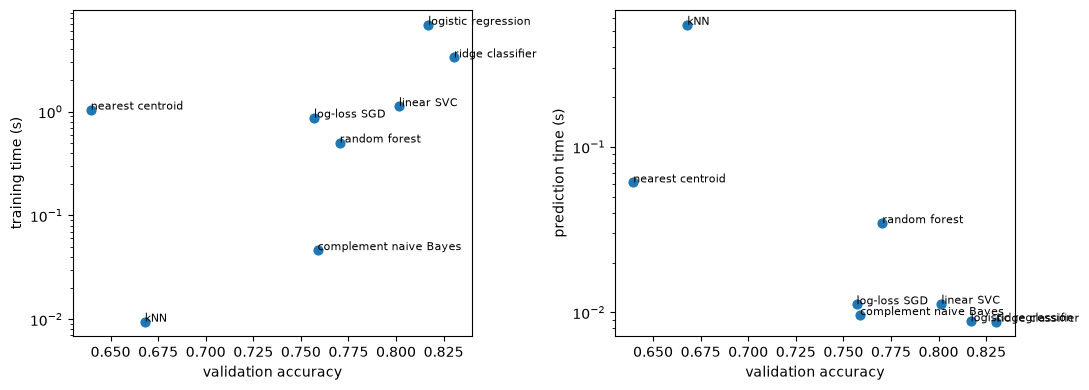

In [11]:
import matplotlib.pyplot as plt

names, score, train_time, test_time = map(np.array, zip(*results))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, t, label in [(axes[0], train_time, "training time (s)"), (axes[1], test_time, "prediction time (s)")]:
    ax.scatter(score.astype(float), t.astype(float), s=40)
    ax.set(yscale="log", xlabel="validation accuracy", ylabel=label)
    for n, x, y in zip(names, score.astype(float), t.astype(float)):
        ax.annotate(n, (x, y), fontsize=8)
plt.tight_layout()
plt.show()

How to read the plots (the exact times depend on your laptop). The original example concludes that for high-dimensional text, linear models are usually the best fit: with thousands of dimensions most classes become linearly separable. Our run agrees: the ridge classifier, logistic regression and the linear SVC reach the highest accuracies. Once trained, all linear models predict at about the same speed, because they share the same prediction function (one weighted sum per class); their training times differ because of the loss and the solver. Complement naive Bayes trains fastest and is still competitive. The random forest trains quickly here because it uses all processor cores, but it is less accurate than the best linear models: trees split on one feature at a time, which suits thousands of sparse columns poorly. k-nearest neighbours has the longest prediction time and, with nearest centroid, the lowest accuracy: each prediction compares the document with every training document, and in this high-dimensional space distances say little (the "curse of dimensionality").

> 📖 **Read more:** [extras/04-sklearn-text-classification-sparse-features.ipynb](extras/04-sklearn-text-classification-sparse-features.ipynb) (scikit-learn gallery): the original benchmark on 20 Newsgroups posts, with confusion matrices and feature effects before and after stripping e-mail metadata.

## 3 · Metrics for more than 1,000 classes: accuracy, macro-F1, rare headings, validation by time

With two classes Session 8 computed precision, recall and F1 for the positive class. With many classes the same measures are computed **per class**, treating that class as positive and all others as negative:

- **precision** of heading k = correct predictions of k / all predictions of k ("when the model says 9503, how often is it right?");
- **recall** of heading k = correct predictions of k / all true members of k ("of all toy decisions, how many does it find?");
- **F1** = 2 × precision × recall / (precision + recall), low if either is low;
- **support** = the number of true members of k.

Three averages summarise the per-class values:

| Average | Definition | Effect with rare classes |
|---|---|---|
| macro | plain mean of the per-class F1 values | every heading counts equally, also one with a single decision |
| weighted | mean weighted by support | dominated by frequent headings |
| micro | computed from all predictions pooled; equals accuracy for single-label tasks | dominated by frequent headings |

By hand with ten decisions: six of 3926, two of 6403, two of 6404. The model gets all six 3926 right, one of each footwear heading, and predicts 3926 for the other two. Precision of 3926 is 6/8, recall 6/6, F1 0.86; F1 is 0.67 for each footwear heading. Macro-F1 = (0.86 + 0.67 + 0.67) / 3 = 0.73, accuracy = 8/10 = 0.80.

Accuracy answers "what share of requests gets the right suggestion?", which drives an officer's workload, so the leaderboard ranks by it. Macro-F1 answers "how well does the model know the tariff as a whole?" and keeps the long tail visible.

Next we check the hand computation. `average=None` returns one F1 per class; `labels=` fixes their order.

In [12]:
y_true = ["3926"] * 6 + ["6403", "6403", "6404", "6404"]
y_pred = ["3926"] * 6 + ["3926", "6403", "3926", "6404"]
print(f1_score(y_true, y_pred, average=None, labels=["3926", "6403", "6404"]).round(2))
print(round(f1_score(y_true, y_pred, average="macro"), 2), accuracy_score(y_true, y_pred))

[0.86 0.67 0.67]
0.73 0.8


**Predict before running:** always predicting 3926 on the validation years. What accuracy, and what macro-F1?

In [13]:
always_3926 = np.repeat("3926", len(valid))
report("always 3926", valid["heading"], always_3926)
for avg in ["macro", "weighted", "micro"]:
    print(f"word model, {avg:8s} F1 {f1_score(valid['heading'], pred, average=avg, zero_division=0):.3f}")

always 3926                      accuracy 0.040  macro-F1 0.000
word model, macro    F1 0.511
word model, weighted F1 0.760
word model, micro    F1 0.772


### Rare headings

A list of 800 per-heading F1 values cannot be read, but two views can: the per-heading report sorted by support, and the mean F1 of headings grouped by how many training decisions they have. `classification_report(..., output_dict=True)` returns the per-class values as a dictionary; the last three rows are the averages, which we drop.

In [14]:
from sklearn.metrics import classification_report

per_heading = pd.DataFrame(classification_report(valid["heading"], pred, output_dict=True,
                                                 zero_division=0)).T.iloc[:-3]
print(per_heading.sort_values("support", ascending=False).head(5).round(2))
print(len(per_heading), "headings in the validation years;", int((per_heading["f1-score"] == 0).sum()),
      "with F1 = 0;", int((per_heading["support"] < 5).sum()), "with fewer than 5 decisions")

      precision  recall  f1-score  support
3926       0.67    0.85      0.75    523.0
9503       0.77    0.96      0.85    372.0
6307       0.74    0.90      0.81    360.0
2106       0.73    0.90      0.81    347.0
4202       0.89    0.95      0.92    325.0
778 headings in the validation years; 237 with F1 = 0; 415 with fewer than 5 decisions


Next we group the headings by their number of training decisions with `pd.cut` and average F1 per group.

In [15]:
n_train = train["heading"].value_counts().reindex(per_heading.index, fill_value=0)
bins = pd.cut(n_train, [-1, 0, 10, 50, 200, np.inf], labels=["0", "1-10", "11-50", "51-200", ">200"])
per_heading["f1-score"].groupby(bins, observed=True).agg(["mean", "count"]).round(2)

,mean,count
count,,
0,0.00,44
1-10,0.36,328
11-50,0.64,250
51-200,0.77,120
>200,0.79,36


F1 rises steeply with the number of training examples, and headings never seen in training cannot be predicted at all. More data for rare headings helps more than tuning the frequent ones: on the public leaderboard, going from the sample to the full training set raises macro-F1 from 0.517 to 0.682 and accuracy from 0.806 to 0.872 (case-study README).

> **Note.** `f1_score` with more than two classes needs `average=`; always say which average you report. Macro-F1 also depends on which classes appear in the evaluation data, so compare macro-F1 values only on the same data.

### Top-k accuracy

An officer can check three suggestions in seconds, so a model whose second or third suggestion is often right is more useful than its accuracy says. **Top-k accuracy** counts a prediction as correct if the true heading is among the k highest-scoring headings. `decision_function` returns one score per heading, `np.argsort(-scores, axis=1)` sorts each row from high to low, and `classes_` maps column numbers to headings.

In [16]:
scores = model.decision_function(valid["description"])
order = np.argsort(-scores, axis=1)
y_val = valid["heading"].to_numpy()
classes = model.classes_
for k in [1, 3, 5, 10]:
    print(f"top-{k:<2d} accuracy {(classes[order[:, :k]] == y_val[:, None]).any(axis=1).mean():.3f}")

top-1  accuracy 0.772
top-3  accuracy 0.838
top-5  accuracy 0.856
top-10 accuracy 0.876


### Validation by time against a random split

A **random split** draws validation decisions from all years; a **split by time** validates on the latest years only. A random split asks "how well does the model classify decisions like the ones it was trained on?"; a split by time asks "how well will it classify next year's requests?", which is the leaderboard's question. Three things make a random split too optimistic here: renewed decisions with near-identical descriptions end up on both sides, the product mix and wording change over the years, and headings changed in the HS 2022 revision appear with their new meaning only in the later years.

**Predict before running:** will the random split report a higher or a lower accuracy than the time split, with the same number of validation decisions? `train_test_split(df, test_size=n, random_state=0)` draws a random split.

In [17]:
from sklearn.model_selection import train_test_split

rand_train, rand_valid = train_test_split(decisions, test_size=len(valid), random_state=0)
random_model = make_pipeline(TfidfVectorizer(min_df=2, sublinear_tf=True), svm())
random_model.fit(rand_train["description"], rand_train["heading"])
report("random split", rand_valid["heading"], random_model.predict(rand_valid["description"]))
report("split by time", valid["heading"], pred)
print("exact repeats of a training description:",
      round(rand_valid["description"].isin(rand_train["description"]).mean(), 3), "(random) vs",
      round(valid["description"].isin(train["description"]).mean(), 3), "(time)")

random split                     accuracy 0.816  macro-F1 0.571
split by time                    accuracy 0.772  macro-F1 0.511


exact repeats of a training description: 0.016 (random) vs 0.004 (time)


Exact repeats explain only a small part of the gap; most of it comes from near-repeats and from change over time. The leaderboard sides with the time split.

**In practice.** Credit-scoring and forecasting teams validate "out of time" for the same reason. Kapoor and Narayanan (2023) list random splits of temporal data among the common forms of leakage in published machine-learning studies.

## 4 · Error analysis and the most informative n-grams

A score says how often a model fails, not why. **Error analysis** means reading a sample of misclassified examples, sorting them into categories and counting. It turns a score into a list of next steps and prevents a common waste of time: tuning hyperparameters when the real problem lies in the data or the task.

```mermaid
flowchart LR
    A["Validation<br/>predictions"] --> B["Where are the errors?<br/>(confusion, top pairs)"]
    B --> C["Read a sample of errors<br/>with keywords and<br/>heading texts"]
    C --> D["Sort into<br/>categories"]
    D --> E["Count per<br/>category"]
    E --> F{"Fixable with<br/>text features?"}
    F -->|yes| G["Change features<br/>or data, re-validate"]
    F -->|no| H["Accept, document,<br/>or route to a person"]
    G --> A
```

A **confusion matrix** counts, for every true class (row), how often each class was predicted (column). With 1,000 headings it has a million cells, so we look at **groups of neighbouring headings** (one chapter) and at the **most frequent pairs** of true and predicted heading.

*The confusion-matrix plot is adapted from [Classification of text documents using sparse features](https://scikit-learn.org/stable/auto_examples/text/plot_document_classification_20newsgroups.html) (scikit-learn developers, BSD-3-Clause).* Next we draw it for the six footwear headings 6401–6406 with `ConfusionMatrixDisplay.from_predictions`; `labels=` restricts it to these headings.

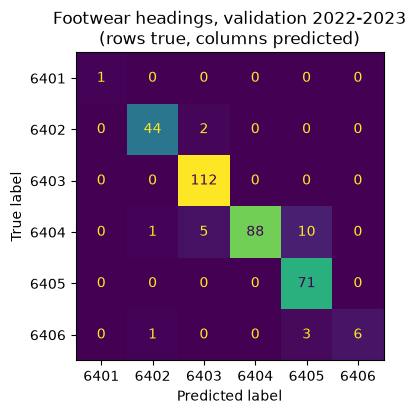

In [18]:
from sklearn.metrics import ConfusionMatrixDisplay

shoes = ["6401", "6402", "6403", "6404", "6405", "6406"]
in64 = valid["heading"].isin(shoes).to_numpy()
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(valid["heading"][in64], pred[in64], labels=shoes, ax=ax, colorbar=False)
ax.set_title("Footwear headings, validation 2022-2023\n(rows true, columns predicted)")
plt.show()

Read along a row: how are the true decisions of one heading spread over the predictions? 6404 (textile uppers) loses decisions to 6405 (other footwear) and 6403 (leather uppers), and 6406 (parts of footwear) has the lowest recall: parts are described with the same words as complete shoes.

Next we count the most frequent true–predicted pairs over all headings and add the heading texts with `.map`.

In [19]:
val = valid.assign(pred=pred)
wrong = val[val["heading"] != val["pred"]]
print(len(wrong), "errors; share inside the right chapter:",
      round((wrong["heading"].str[:2] == wrong["pred"].str[:2]).mean(), 2))
pairs = wrong[["heading", "pred"]].value_counts().head(6).rename("n").reset_index()
pairs["true_name"] = pairs["heading"].map(nomenclature["heading_description"]).str[:35]
pairs["pred_name"] = pairs["pred"].map(nomenclature["heading_description"]).str[:35]
pairs

3003 errors; share inside the right chapter: 0.3


,heading,pred,n,true_name,pred_name
0,8524,8548,17,"Flat panel display modules, whether",Electrical parts of machinery or ap
1,8539,9405,13,Lamps; electric filament or dischar,Luminaires and light fittings; incl
2,8524,8529,12,"Flat panel display modules, whether",Transmission apparatus; parts suita
3,8708,3926,11,Motor vehicles; parts and accessori,Articles of plastics and articles o
4,3924,3926,11,"Tableware, kitchenware, other house",Articles of plastics and articles o
5,7308,7326,11,Structures of iron or steel and par,"Iron or steel; articles, n.e.c. in"


### Reading 20 errors

For a multilingual corpus two reading aids make error analysis possible for everyone: the English **keywords** customs assigned to each training decision and the English **heading texts** from the nomenclature. Neither is a model input. Next we draw 20 errors with a fixed seed, so that the whole class reads the same decisions, and show them side by side.

In [20]:
pd.set_option("display.max_colwidth", 110)
errors20 = wrong.sample(20, random_state=1)
table = pd.DataFrame({
    "lang": errors20["language"],
    "true": errors20["heading"] + " " + errors20["heading"].map(nomenclature["heading_description"]).str[:40],
    "predicted": errors20["pred"] + " " + errors20["pred"].map(nomenclature["heading_description"]).str[:40],
    "keywords": errors20["keywords"].str[:70],
})
table

,lang,true,predicted,keywords
41846,nl,"9605 Travel sets; for personal toilet, sewing","3301 Oils; essential (concretes, absolutes);","AEROPLANES,BOTTLES,EMPTY,FOR FILLING,OF PLASTICS,SPATULAS,TRANSPARENT,"
45577,fr,9027 Instruments and apparatus; for physical,8543 Electrical machines and apparatus; havin,"ACIDS,AS MODULE,CHROMOTOGRAPHS,FOR MEDICAL USE,FOR PHARMACEUTICALS,PUM"
43912,nl,"8214 Cutlery; other articles, (e.g. hair clip","9503 Tricycles, scooters, pedal cars and simi","ART. OF CUTLERY, CUTTING UTENSILS,HOLDERS,KNIVES,OF BASE METALS,OF PLA"
43781,nl,"8421 Centrifuges, including centrifugal dryer",3926 Articles of plastics and articles of oth,"AS CYLINDERS,CHROMOTOGRAPHS,CONNECTIONS,FILTERS,FOR BUILDING-IN,LIQUID"
38644,cs,"4419 Tableware and kitchenware, of wood","7318 Screws, bolts, nuts, coach screws, screw","ARTICLES OF WOOD,BIRCH,CUTLERY, TABLEWARE,DISPOSABLE,MACHINE-WORKED,NA"
48433,cs,"2404 Products containing tobacco, reconstitut",3824 Prepared binders for foundry moulds or c,"BILBERRIES,HERBS,MINT,NICOTINE,THYME,WITHOUT TOBACCO"
41515,fr,4421 Wooden articles n.e.c. in heading no. 44,"9403 Furniture and parts thereof, n.e.c. in c","ARTICLES OF WOOD,FOR HYGIENIC USE,LAVATORY COVERS,LAVATORY PANS,LAVATO"
42080,fr,"7013 Glassware of a kind used for table, kitc",9405 Luminaires and light fittings; including,"BELL JARS,BY STORAGE BATTERIES,FOR DECORATION,GATHERED MECHANICALLY,GL"
44630,es,"7606 Aluminium; plates, sheets and strip, thi",7210 Iron or non-alloy steel; flat-rolled pro,"AS ROLLS,AS SHEETS,METAL BLADES,METAL SHEETS,OF ALUMINIUM,STRIPS"
37022,sv,"8536 Electrical apparatus for switching, prot",3926 Articles of plastics and articles of oth,"FOR OPTICAL FIBRE CABLES,FOR PROTECTION,OF PLASTICS,PROTECTIVE CASINGS"


The course team sorted these 20 errors by hand into categories. Your own categories may differ; the point is to count.

| Category | Example in the 20 errors | Count |
|---|---|---|
| borderline between related headings (the legal notes decide) | orange drink 2202/2106, curry 0910/2103 | 6 |
| rare language or few training examples | Czech, Slovak, Bulgarian, Polish, Spanish descriptions | 5 |
| material versus function (the model follows the material, the tariff the function) | a plastic splice box (8536, predicted 3926) | 4 |
| technical or chemical knowledge needed | | 2 |
| sets and composite goods | a travel set of bottles (9605, predicted 3301) | 1 |
| new heading after the HS 2022 revision | a nicotine product (2404) | 1 |
| no clear reason | | 1 |

Eleven of twenty errors (borderline, material versus function, sets) depend on classification rules rather than vocabulary: no description-only model sees the General Interpretative Rules and the chapter notes of the tariff. Five involve languages with few training decisions, which suggests more data or character n-grams. Error analysis therefore also gives an honest upper bound on what a better text representation alone can achieve.

### The most informative n-grams per class

In a linear model each feature has one **coefficient** per class. A large positive coefficient means that the n-gram pushes the score towards that class. Because TF-IDF rows all have length 1, sorting a class's coefficients ranks its most informative n-grams. This is also a check for **shortcuts**: features that predict the label for reasons unrelated to the goods.

Next we read the coefficients from the fitted pipeline: `named_steps` gives its parts, `coef_[k]` the weights of class k, and `np.argsort(...)[::-1][:8]` the eight largest.

In [21]:
vec, clf = model.named_steps["tfidfvectorizer"], model.named_steps["sgdclassifier"]
names = vec.get_feature_names_out()
for heading in ["6403", "6404", "9503"]:
    k = list(clf.classes_).index(heading)
    print(heading, list(names[np.argsort(clf.coef_[k])[::-1][:8]]))

6403 ['cuir', '6403', '24', 'leder', '1200', 'leather', 'naturel', '24cm']
6404 ['kunststoff', 'textile', '1910', 'caoutchouc', '1100', 'sole', 'spinnstoffen', '6404']
9503 ['jouet', 'spielzeug', 'speelgoed', 'leksak', 'jouets', 'enfants', 'toy', 'children']


The model learns the same concept separately in each language (toy words in French, German, Dutch, Swedish and English), the material words of the legal text dominate the footwear headings, and **numbers** appear among the strongest features. Traders and customs often quote tariff codes in the description. The data replace numbers that repeat the decision's *own* code by `<CODE>`, but a quoted heading survives when it comes with a different subheading.

**Predict before running:** what share of the validation descriptions contain their own four-digit heading as a number, and how accurate is the model on them? The pattern `(?<!\d)6403(?!\d)` finds 6403 not preceded or followed by another digit.

In [22]:
import re

has_number = pd.Series([bool(re.search(rf"(?<!\d){h}(?!\d)", t))
                        for h, t in zip(valid["heading"], valid["description"])], index=valid.index)
print("share quoting their heading:", round(has_number.mean(), 3))
print(val.groupby(has_number).apply(lambda g: round((g["heading"] == g["pred"]).mean(), 3)).to_dict())

share quoting their heading: 0.246


{False: 0.705, True: 0.98}


Is this leakage? No: the numbers are part of what the trader or customs wrote, and test descriptions contain them too, so the feature is available at prediction time. But it changes how we read the score: part of the task is "read the code that is already there", and the hard part is the rest. Report both numbers.

> **Note.** Coefficients are comparable only when features are on the same scale and not strongly correlated. `leder` and `leather` share their signal across languages, so neither coefficient alone tells the full story. Treat the ranking as a diagnostic, not as a causal statement about words.

**In practice.** Andrew Ng's *Machine Learning Yearning* (2018) recommends reading about 100 misclassified examples by hand and counting error categories before deciding what to improve. Northcutt, Athalye and Mueller (2021) found label errors in the test sets of ten widely used benchmarks, using a model's confident errors to find them.

### Average feature effects per class (depth: self-study or if time allows)

*Adapted from [Classification of text documents using sparse features](https://scikit-learn.org/stable/auto_examples/text/plot_document_classification_20newsgroups.html) (scikit-learn developers, BSD-3-Clause), on EBTI data.*

A large coefficient for a word that almost never occurs has little effect on predictions. The **average feature effect** multiplies each coefficient by the mean value of the feature over the training documents, so frequent and informative words rise to the top. Next we compute it for the four footwear headings 6402–6405 of the four-chapter task and plot the union of their top five words as grouped bars. A `RidgeClassifier` is fitted first, as in the original example.

In [23]:
ridge = RidgeClassifier(tol=1e-2, solver="sparse_cg").fit(X_train, y_train)
feature_names = vec_small.get_feature_names_out()
labels = ["6402", "6403", "6404", "6405"]
rows = [list(ridge.classes_).index(h) for h in labels]
effects = ridge.coef_[rows] * np.asarray(X_train.mean(axis=0)).ravel()
top_idx = np.unique(np.concatenate([np.argsort(e)[-5:] for e in effects]))
print(pd.DataFrame({h: feature_names[np.argsort(e)[-5:][::-1]] for h, e in zip(labels, effects)}))

       6402        6403          6404        6405
0      6402        6403      oberteil  spinnstoff
1      1210       leder    laufsohlen    oberteil
2      6401        1200    kunststoff  laufsohlen
3  genannte  hauptsohle          6404         den
4    andere          cm  spinnstoffen      andere


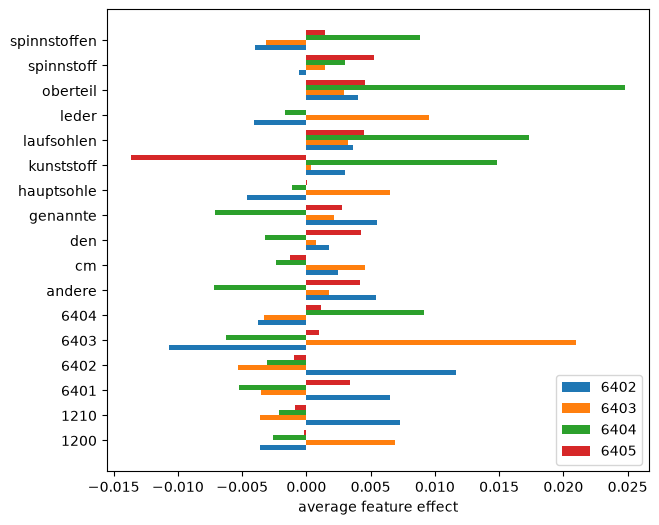

In [24]:
fig, ax = plt.subplots(figsize=(7, 6))
y_locs = np.arange(len(top_idx))
for i, h in enumerate(labels):
    ax.barh(y_locs + (i - 1.5) * 0.2, effects[i, top_idx], height=0.2, label=h)
ax.set(yticks=y_locs, yticklabels=feature_names[top_idx], xlabel="average feature effect")
ax.legend(loc="lower right")
plt.show()

The most predictive words are mostly positive for one heading and negative for the others: `leder` pushes towards 6403, `spinnstoffen` (textile materials) towards 6404. Two things stand out. Quoted codes such as `6402` or `6404` are among the strongest effects, and the words are German: the average effect weights by frequency, and most footwear decisions are German. Words shared by several headings (`oberteil`, upper; `laufsohlen`, outer soles) have bars for more than one heading, which is where confusions start.

## 5 · Leakage through the customs' justification

**Target leakage** (Sessions 7 and 9) means that a feature contains information about the label that will not be available when the model is used. Every training decision has a column `classification_justification`, the text in which customs explain their classification. It is written *with* the decision and usually names the result, for example:

> CLASSIFICATION HAS BEEN DETERMINED IN ACCORDANCE WITH THE FOLLOWING: GIR 1 HAS BEEN USED TO CLASSIFY THE PRODUCT BY THE TERMS OF HEADING 4303 ...

It is like grading an exam with the answer key stapled to each paper. A new request has no justification, and the test set does not contain the column.

Next we measure how often the justification names the heading, and how far a rule gets that simply reads its first four-digit number. `str.extract(pattern, expand=False)` returns the first match of a capture group.

In [25]:
just = decisions["classification_justification"].fillna("")
print("justification contains the heading:", round(np.mean([h in j for h, j in zip(decisions["heading"], just)]), 2))
first_number = just.str.extract(r"\b(\d{4})\b", expand=False)
print("first four-digit number = heading: ", round((first_number == decisions["heading"]).mean(), 2))

justification contains the heading: 0.7


first four-digit number = heading:  0.64


Now the careless notebook: append the justification to the description and validate with a random split inside the training years. Then apply the model where it will be used: to the decisions of 2022–2023, which, like a new request, have only a description.

**Predict before running:** which of the two models will be better in use?

In [26]:
with_just = decisions["description"] + " " + just
past = (year <= 2021).to_numpy()
tr, va = train_test_split(np.flatnonzero(past), test_size=0.2, random_state=0)
later = np.flatnonzero(~past)
y = decisions["heading"]
for name, X in [("description only", decisions["description"]), ("+ justification", with_just)]:
    m = make_pipeline(TfidfVectorizer(min_df=2, sublinear_tf=True), svm()).fit(X.iloc[tr], y.iloc[tr])
    acc_val = accuracy_score(y.iloc[va], m.predict(X.iloc[va]))
    acc_use = accuracy_score(y.iloc[later], m.predict(decisions["description"].iloc[later]))
    print(f"{name:17s} validation {acc_val:.3f}   in use (description only) {acc_use:.3f}")

description only  validation 0.806   in use (description only) 0.757


+ justification   validation 0.959   in use (description only) 0.713


Validation reports a large jump. In use, where only the description exists, the leaking model is *worse* than the honest one: it learned to rely on a text that is missing, and learned less from the description itself.

No validation scheme detects this, because the justification is present in every validation decision as well. The only protection is to ask, for every column, *"would I have this value at the moment of prediction?"*, and to answer from how the data are produced, not from the scores.

*The following example is summarised from [Classification of text documents using sparse features](https://scikit-learn.org/stable/auto_examples/text/plot_document_classification_20newsgroups.html) (scikit-learn developers, BSD-3-Clause).* The same kind of leak appears in the classic 20 Newsgroups benchmark: by default the posts contain e-mail headers, signatures and quoted earlier messages. In that example, the word "caltech" is among the most predictive features for the atheism newsgroup, because sender addresses in the metadata identify regular posters. Stripping headers, footers and quotes lowers the score, but the remaining model learns from the content, which is what the task intends.

> **Note.** A large jump in the validation score from one new column is a warning sign, not a success. For the leaderboard, never use `classification_justification`, `keywords`, `cn_code`, `chapter`, `status`, `end_date` or `invalidation_reason` as inputs. Reading them during error analysis is fine.

**In practice.** Kaufman et al. (2012) use the KDD Cup 2008 breast-cancer data, where patient identifiers predicted the label because of how the data had been assembled, as a textbook case of leakage. In churn data, fields such as "reason for leaving" are filled only for customers who have already left.

## 6 · Dimensionality reduction with truncated SVD

The TF-IDF matrix has tens of thousands of sparse columns. **Truncated singular value decomposition** (truncated SVD) approximates it by k dense columns, say 100. Each new column, a **component**, is a weighted combination of words that tend to occur together. Applied to a document-term matrix the method is called **latent semantic analysis** (LSA; Deerwester et al., 1990). In a picture: X ≈ U Σ Vᵀ, where V (words × k) describes each component by its word weights and U Σ (documents × k) gives each document's coordinates on the components.

Truncated SVD is closely related to PCA (Session 11). PCA first subtracts the column means, which would turn every zero into a non-zero number and destroy sparsity; truncated SVD works on the sparse matrix directly.

```mermaid
flowchart LR
    X["TF-IDF matrix<br/>documents x words<br/>sparse"] -->|"TruncatedSVD(k=100)"| Z["LSA features<br/>documents x 100<br/>dense"]
    Z --> P["2-D plot,<br/>clustering (Session 11)"]
    Z --> M["Classifier or trees<br/>(compact features)"]
    X -->|"components_"| W["Word weights<br/>per component"]
```

Next we fit 100 components on the training TF-IDF matrix of the word model. `explained_variance_ratio_` is the share of variance each component keeps; we print the top and bottom words of components 1–3 (component 0 is close to the average document).

In [27]:
from sklearn.decomposition import TruncatedSVD

T = vec.transform(train["description"])
svd = TruncatedSVD(n_components=100, random_state=0).fit(T)
print("variance kept by 100 components:", round(svd.explained_variance_ratio_.sum(), 2))
for i in [1, 2, 3]:
    c = svd.components_[i]
    print(i, list(names[np.argsort(c)[::-1][:6]]), "vs", list(names[np.argsort(c)[:4]]))

variance kept by 100 components: 0.19
1 ['de', 'en', 'la', 'et', 'un', 'une'] vs ['oberteil', 'aus', 'mit', 'laufsohlen']
2 ['oberteil', 'laufsohlen', 'spinnstoff', 'kunststoff', 'schuhe', 'antrag'] vs ['die', 'es', 'um', 'handelt']
3 ['een', 'van', 'met', 'het', 'voor', 'volgende'] vs ['la', 'et', 'un', 'une']


**Predict before reading the output:** do the first components separate product groups or languages?

The first components separate **languages**, because words of one language co-occur with each other; topics such as footwear appear only in some components. Next we use 300 LSA components as classifier input. `Normalizer()` rescales each row to length 1 again after the projection.

In [28]:
from sklearn.preprocessing import Normalizer

t0 = time.perf_counter()
lsa = make_pipeline(TfidfVectorizer(min_df=2, sublinear_tf=True),
                    TruncatedSVD(n_components=300, random_state=0), Normalizer(), svm())
lsa.fit(train["description"], train["heading"])
report("linear SVM on 300 LSA components", valid["heading"], lsa.predict(valid["description"]), t0)
report("linear SVM on sparse TF-IDF", valid["heading"], pred)

linear SVM on 300 LSA components accuracy 0.615  macro-F1 0.296    25 s
linear SVM on sparse TF-IDF      accuracy 0.772  macro-F1 0.511


The compact representation is much weaker for classification. LSA is mainly a tool for exploration, for plots and for methods that need dense input (k-means, nearest-neighbour search, tree models), and the historical step towards the learned embeddings of Session 14, which do map texts of different languages into one space.

> **Note.** The sign of an SVD component is arbitrary. Interpret components by their top *and* bottom words, and do not expect every component to have a clear meaning.

**In practice.** LSA was developed at Bellcore for information retrieval (Deerwester et al., 1990), so that a search for "car" could also find documents about "automobiles". Landauer and Dumais (1997) reported that LSA trained on an encyclopedia answered the synonym questions of the TOEFL test about as well as applicants from non-English-speaking countries.

### Clustering descriptions with LSA and k-means (depth: self-study or if time allows)

*Adapted from [Clustering text documents using k-means](https://scikit-learn.org/stable/auto_examples/text/plot_document_clustering.html) (scikit-learn developers, BSD-3-Clause), on EBTI data.*

Clustering is unsupervised (Session 11), but when labels exist we can use them to judge the clusters:

- **homogeneity**: how much each cluster contains members of a single class;
- **completeness**: how much the members of a class end up in the same cluster;
- **V-measure**: the harmonic mean of the two;
- **adjusted Rand index** (ARI): how often pairs of documents are grouped consistently with the classes, adjusted so that random labels score 0 on average;
- the **silhouette coefficient** needs no labels; it compares distances within and between clusters.

To avoid clusters by language, we use only German decisions of the four chapters of the benchmark and ask k-means for four clusters.

In [29]:
from sklearn.cluster import KMeans
from sklearn import metrics

de4 = decisions[(decisions["language"] == "de") & decisions["chapter"].isin(chapters)]
labels_true = de4["chapter"].to_numpy()
vec_de = TfidfVectorizer(max_df=0.5, min_df=5)
X_tfidf = vec_de.fit_transform(de4["description"])
print(f"{X_tfidf.shape[0]:,} documents, {X_tfidf.shape[1]:,} features, "
      f"non-zero share {X_tfidf.nnz / np.prod(X_tfidf.shape):.3f}; chapter sizes",
      de4["chapter"].value_counts().sort_index().to_dict())

8,999 documents, 7,715 features, non-zero share 0.007; chapter sizes {'39': 1918, '64': 1393, '85': 4333, '95': 1355}


k-means optimises a non-convex objective, so its result depends on the random start. On sparse, high-dimensional text it can place a centre on an isolated document that then stays a cluster of its own. Next we run it five times with one start each (`n_init=1`) and print the cluster sizes; `np.unique(..., return_counts=True)` counts the members per cluster.

In [30]:
for seed in range(5):
    km = KMeans(n_clusters=4, max_iter=100, n_init=1, random_state=seed).fit(X_tfidf)
    print("cluster sizes:", np.unique(km.labels_, return_counts=True)[1])

cluster sizes: [1361 3475 3238  925]
cluster sizes: [1237 3236 4400  126]
cluster sizes: [3251 3684  702 1362]
cluster sizes: [3349 1362 3254 1034]


cluster sizes: [1361 3483 3231  924]


The cluster sizes change with the seed and can be very unbalanced compared with the chapter sizes. Next we write a function that fits a clustering several times with different seeds and reports the mean and spread of each score.

In [31]:
def fit_and_evaluate(km, X, name, n_runs=3):
    scores = {"homogeneity": [], "completeness": [], "V-measure": [], "ARI": [], "silhouette": []}
    for seed in range(n_runs):
        km.set_params(random_state=seed).fit(X)
        scores["homogeneity"].append(metrics.homogeneity_score(labels_true, km.labels_))
        scores["completeness"].append(metrics.completeness_score(labels_true, km.labels_))
        scores["V-measure"].append(metrics.v_measure_score(labels_true, km.labels_))
        scores["ARI"].append(metrics.adjusted_rand_score(labels_true, km.labels_))
        scores["silhouette"].append(metrics.silhouette_score(X, km.labels_, sample_size=2000, random_state=0))
    print(name, {k: f"{np.mean(v):.3f} ± {np.std(v):.3f}" for k, v in scores.items()})


fit_and_evaluate(KMeans(n_clusters=4, max_iter=100, n_init=5), X_tfidf, "k-means on TF-IDF, n_init=5:\n ")

k-means on TF-IDF, n_init=5:
  {'homogeneity': '0.750 ± 0.000', 'completeness': '0.750 ± 0.000', 'V-measure': '0.750 ± 0.000', 'ARI': '0.644 ± 0.000', 'silhouette': '0.050 ± 0.000'}


All scores have a maximum of 1. Next we reduce the TF-IDF matrix to 100 LSA components first, normalise the rows again, and cluster with a single start.

In [32]:
lsa_de = make_pipeline(TruncatedSVD(n_components=100, random_state=0), Normalizer(copy=False))
X_lsa = lsa_de.fit_transform(X_tfidf)
print(f"variance kept: {lsa_de[0].explained_variance_ratio_.sum():.1%}")
kmeans = KMeans(n_clusters=4, max_iter=100, n_init=1)
fit_and_evaluate(kmeans, X_lsa, "k-means on LSA, n_init=1:\n ")

variance kept: 38.7%


k-means on LSA, n_init=1:
  {'homogeneity': '0.760 ± 0.002', 'completeness': '0.764 ± 0.013', 'V-measure': '0.762 ± 0.006', 'ARI': '0.656 ± 0.024', 'silhouette': '0.121 ± 0.003'}


Compare the two lines: with LSA, a single start reaches slightly higher label-based scores than five starts on the raw TF-IDF matrix, and it is much cheaper. The original example finds the same on news posts and explains it by the curse of dimensionality, which hurts k-means on raw text. The silhouette is low in both cases; strictly, it should not be compared across spaces of different dimension.

Because the SVD can be inverted approximately, we can map the cluster centres back to the word space with `inverse_transform` and read the top terms of each cluster.

In [33]:
centroids = lsa_de[0].inverse_transform(kmeans.cluster_centers_)
terms = vec_de.get_feature_names_out()
for i, row in enumerate(centroids.argsort()[:, ::-1][:, :8]):
    members = pd.Series(labels_true[kmeans.labels_ == i]).value_counts().head(2).to_dict()
    print(f"cluster {i}: {' '.join(terms[row])}  | chapters {members}")

cluster 0: oberteil laufsohlen kunststoff spinnstoff antrag schuhe genannte 6403  | chapters {'64': 1382}
cluster 1: zur zum mm bestimmt oder gehäuse abbildung beipack  | chapters {'85': 3632, '95': 35}
cluster 2: spannung elektrischen weniger eine stromkreisen 1000 zum steckvorrichtung  | chapters {'85': 672}
cluster 3: es sich um handelt cm im ist 3926  | chapters {'39': 1899, '95': 1320}


Read the clusters against the chapters: footwear forms a clean cluster of its own, electrical goods split into two clusters (one around voltages and circuits), and plastics and toys end up together, held by the general phrasing "es handelt sich um" (it is a ...) and the quoted code 3926. Clusters follow whatever co-occurs most, which is not always what we care about.

> 📖 **Read more:** [extras/05-sklearn-document-clustering-lsa.ipynb](extras/05-sklearn-document-clustering-lsa.ipynb) (scikit-learn gallery): the original example on news posts, with `MiniBatchKMeans`, a `HashingVectorizer` + `TfidfTransformer` + LSA pipeline, and a summary plot of all clustering scores and times.

## 7 · The limits of word counts

Bag-of-words, TF-IDF and n-grams share four blind spots:

1. **Other languages and synonyms.** "Spielzeugauto aus Kunststoff", "Voiture jouet en matière plastique" and "Toy car of plastics" describe the same good but share no word. The model must learn each language from labelled examples; for Bulgarian or Slovak there are few.
2. **Word order beyond n words.** "Shoes with a textile upper and a leather sole": bigrams help only if material and part stand next to each other.
3. **Ambiguity.** "Zubehör" (accessories) or "set" mean different things for different goods; one column has many meanings.
4. **Unknown words and short texts.** A word that is not in the training vocabulary gets no column, and a short description gives the model little to go on.

Each limit has a classic patch: n-grams (order), stemming and LSA (synonyms within one language), character n-grams (compounds, unknown words). None solves the problem in general, because all of them still represent a word by its identity, not by its meaning. **Language models** learn from large amounts of unlabelled text, in many languages, that "jouet", "Spielzeug" and "toy" occur in similar contexts, and represent texts as dense vectors in which such descriptions are close (Session 14).

**Predict before running:** what is the cosine similarity of the TF-IDF vectors of the three toy-car descriptions? `cosine_similarity` compares every row with every other row.

In [34]:
from sklearn.metrics.pairwise import cosine_similarity

same_good = ["Spielzeugauto aus Kunststoff", "Voiture jouet en matière plastique", "Toy car of plastics"]
print(cosine_similarity(TfidfVectorizer().fit_transform(same_good)).round(2))

[[1. 0. 0.]
 [0. 1. 0.]
 [0. 0. 1.]]


Next a short German description of a replacement head for electric toothbrushes. We check whether its words are in the vocabulary of the word model (`in vec.vocabulary_`) and what the model predicts.

In [35]:
short = "Aufsteckbürste für elektrische Zahnbürsten"
print({w: w in vec.vocabulary_ for w in ["aufsteckbürste", "elektrische", "zahnbürsten"]})
guess = model.predict([short])[0]
print(guess, nomenclature.loc[guess, "heading_description"][:50], "| true heading would be 9603 (brushes)")

{'aufsteckbürste': False, 'elektrische': True, 'zahnbürsten': False}
6301 Blankets and travelling rugs | true heading would be 9603 (brushes)


```mermaid
timeline
    title From word counts to language models
    1972 : idf weighting (Spärck Jones)
    1990 : LSA, truncated SVD of the term matrix
    2003 : Topic models (LDA)
    2013 : word2vec word embeddings
    2017 : Transformer and attention
    2018 : BERT and GPT, pre-trained language models
    2019 : Multilingual sentence embeddings
```

> **Note.** Keep the TF-IDF classifier as the baseline for every later text model in the project. A language model is worth its extra cost only if it beats this baseline on the same validation years by a margin that matters (Session 14).

**In practice.** Many production search systems still use BM25 or TF-IDF for a first, cheap retrieval step and a language model only for re-ranking the top results, combining the speed of counts with the semantics of embeddings (Session 15).

## Worked example · Leaderboard round L1

The practice task of this block: a first leaderboard submission with a TF-IDF classifier. We take the word model chosen on the validation years, refit it on all 50,000 sample decisions (2017–2023), predict the 113,188 test decisions and check the file before submitting.

In [36]:
t0 = time.perf_counter()
final = make_pipeline(TfidfVectorizer(min_df=2, sublinear_tf=True), svm())
final.fit(decisions["description"], decisions["heading"])
submission = pd.DataFrame({"id": test["id"], "heading": final.predict(test["description"])})
print(submission.shape, f"in {time.perf_counter() - t0:.0f} s")
print(submission["heading"].value_counts(normalize=True).head(5).round(3).to_dict())

(113188, 2) in 27 s
{'3926': 0.052, '9503': 0.037, '2106': 0.035, '6307': 0.032, '4202': 0.031}


Checks before submitting: one row per test decision, unique ids, four-digit headings. `assert` stops with an error if a condition is false. We write the file to a temporary folder (`tempfile.gettempdir()`), not into the course repository; in your team repository, write it to your own project folder.

In [37]:
import tempfile

assert len(submission) == len(test) and submission["id"].is_unique
assert submission["heading"].str.fullmatch(r"\d{4}").all()
path = Path(tempfile.gettempdir()) / "submission-L1-tfidf.csv"
submission.to_csv(path, index=False)
print("written:", path.name, f"({path.stat().st_size / 1e6:.1f} MB)")

written: submission-L1-tfidf.csv (1.5 MB)


To score a file, upload it to the course leaderboard, or run the scorer where the solution file is available (lecturer):

```bash
uv run python case-study/score.py submission-L1-tfidf.csv
```

The next cell does the same if `case-study/data/instructor/solution.csv` exists, and prints only the public (2024) scores; the private years stay hidden until the end of the course.

In [38]:
import sys

solution = Path("case-study/data/instructor/solution.csv")
if solution.exists():
    sys.path.insert(0, "case-study")
    from score import score

    result = score(submission, pd.read_csv(solution, dtype=str))
    print({k: round(v, 4) for k, v in result.items() if k.startswith("public")})
else:
    print("No solution file here: upload the CSV to the course leaderboard instead.")

{'public_accuracy': 0.8033, 'public_macro_f1': 0.5177}


The public accuracy is close to the 0.806 that the case-study README lists for this kind of model on the sample (its settings differ slightly) and above the validation accuracy of 0.772, because the final model is trained on more decisions. The README lists 0.872 when the model is trained on all 309,529 decisions. Training on the full set takes a few minutes and several GB of memory; set `RUN_FULL = True` in the next cell to try it (it writes to the temporary folder as well).

In [39]:
RUN_FULL = False
if RUN_FULL:
    full = pd.read_parquet("case-study/data/train.parquet", columns=["description", "heading"])
    big = make_pipeline(TfidfVectorizer(min_df=2, sublinear_tf=True, max_features=400_000),
                        SGDClassifier(loss="hinge", alpha=2e-6, max_iter=20, tol=None, random_state=0, n_jobs=-1))
    big.fit(full["description"], full["heading"])
    pd.DataFrame({"id": test["id"], "heading": big.predict(test["description"])}).to_csv(
        Path(tempfile.gettempdir()) / "submission-L1-tfidf-full.csv", index=False)
else:
    print("Full training set skipped (RUN_FULL = False).")

Full training set skipped (RUN_FULL = False).


Record the submission in the team log: model, settings, validation accuracy and macro-F1, and leaderboard scores. Rounds L2 and L3 are compared against it.

## Check your understanding

1. A model predicts 9503 for 40 decisions, 30 of them correctly; the validation set has 120 decisions of 9503. Compute precision, recall and F1 for 9503.
2. Always predicting 3926 gives an accuracy of about 0.04 and a macro-F1 close to 0. Why does macro-F1 punish this rule so much more, and which of the two would the head of a classification unit care about first?
3. Why is a random train-validation split more optimistic than a split by year on this data? Name two reasons.
4. Descriptions that quote their heading number are almost always classified correctly. Is this leakage? Compare with the justification: when is each text written?
5. A teammate adds `keywords` to the description and reports 0.93 validation accuracy. What do you expect on the leaderboard, and how do you show it without submitting?

## Exercises (30 min)

Work in pairs. The lecturer picks which exercises to set; there are more than fit into 30 minutes. Solve *Paper* tasks without a laptop first. The *Code* tasks use `model`, `pred`, `val`, `train`, `valid` and `nomenclature` from the cells above; the last exercises lead into the team project.

### 2.1 · Naive Bayes by hand

*Paper · 15 min*

> Training data: negative "just plain boring", "entirely predictable and lacks energy", "no surprises and very few laughs"; positive "very powerful", "the most fun film of the summer". With add-one smoothing (vocabulary of 20 words), classify "predictable with no fun".
>
> *Stretch:* what happens without smoothing?

*Source:* [Jurafsky & Martin, *Speech and Language Processing* (3rd ed. draft), Appendix B: Naive Bayes, worked example](https://web.stanford.edu/~jurafsky/slp3/B.pdf)

*Your answer:*

### 2.2 · Humans against the baseline

*Class · 15 min*

> Classify ten descriptions into HS chapters by hand. How does the class compare with TF-IDF?
>
> The cell below shows ten English descriptions from the validation years and the list of chapters. Write down one two-digit chapter per description (the class may vote). Then compare your answers with the true chapters and with the chapters of the model's predictions (`val["pred"].str[:2]`).

*Source:* original exercise for this course; background: [Karpathy (2014), "What I learned from competing against a ConvNet on ImageNet"](http://karpathy.github.io/2014/09/02/what-i-learned-from-competing-against-a-convnet-on-imagenet/)

In [40]:
# Setup: ten English descriptions and the list of chapters.
ten = val[val["language"] == "en"].sample(10, random_state=7)
for i, text in enumerate(ten["description"], start=1):
    print(i, " ".join(text.split())[:200])
chapter_names = nomenclature.drop_duplicates("chapter").set_index("chapter")["chapter_description"].str[:60]
print(chapter_names.to_string()[:1500], "...")

1 Wearable magnified explorer glasses For children perfect for scientific observation of nature; a key element of STEM based learning Easily flip between 2x and 8x magnification to get a closer look at 
2 ALL TERRAIN VEHICLE (ATV) THIS ATV HAS ONE SEAT ONLY AND IS FITTED WITH ACKERMAN STEERING WHICH IS CONTROLLED BY A HANDLE BAR.THE ENGINE POWER IS 37KW.IT IS EQUIPPED WITH A TOWING HITCH AND HAS A MINU
3 Single-use assembly for bioprocessing without filters: Bags and tubing with fittings. The assembly consists of single-use plastic components connected to each other for fluid transfer and storage of b
4 Hydrolysed chicken collagen It appears as white to slightly yellowish hygroscopic powder
5 Food preparation with coconut oil for spreading. Presented in packages of 150g, 200g, 500g, 3kg, 5kg, 11kg. Ingredients: Water, Coconut Oil (22%), Starch, Sea Salt (0.8%), Flavourings, Olive Extract, 
6 BLUETOOTH HEADPHONES FOR USE WITH SMART MOBILE TELEPHONES, TO PROVIDE A HANDS-FREE OPTION. THE 

*Your answer:*

### 2.3 · The fallback heading of chapter 39

*Code · 15 min*

> Section 4 read the confusion matrix of the footwear headings. Do the same for the plastic articles 3923 (containers, closures), 3924 (tableware, household articles), 3925 (builders' ware) and 3926 (other articles of plastics). Which heading acts as the model's fallback? Compute precision and recall of 3926 from the matrix and check them with `classification_report`.

*Source:* original exercise for this course.

### 2.4 · Ten errors in another language

*Pairs · 15 min*

> Draw ten misclassified **French** (or Polish) decisions from the validation years with `random_state=2`. Read each one with its English keywords and the English texts of the true and the predicted heading, and give each one category from the list in section 4 (borderline, material versus function, rare language, technical, set, new heading, unclear). Does the distribution differ from the 20 errors of section 4?

*Source:* original exercise for this course; background: Ng, *Machine Learning Yearning* (2018), chapters on error analysis.

### 2.5 · What does the model rely on for two other headings?

*Code · 10 min*

> List the twelve n-grams with the largest coefficients for heading 2106 (food preparations not elsewhere specified) and 9405 (luminaires and lighting fittings). How many of them are numbers, how many are words in German, French or English? Would you trust the model for a Greek description of a lamp?

*Source:* original exercise for this course.

### 2.6 · Humans write the classifier

*Paper · 10 min*

> In two minutes, write five words that signal a positive film review and five that signal a negative one. A review is classified by counting hits; ties are guessed. Predict your accuracy. Then compare in class.

*Source:* [Pang, Lee & Vaithyanathan (2002), "Thumbs up? Sentiment classification using machine learning techniques", EMNLP](https://aclanthology.org/W02-1011/)

*Your answer:*

### 2.7 · Improve the classifier

*Pairs · 20 min*

> Pick one error category from section 4 (or from exercise 2.4) and make **one** change to the word model that targets it, for example `min_df`, `max_df`, `ngram_range`, `sublinear_tf`, `alpha`, `class_weight="balanced"`, or a cleaning step before the vectoriser. Train on 2017–2021 and report on 2022–2023: accuracy, macro-F1, and accuracy on the descriptions **without** a quoted heading number (`~has_number`). Write one line for your team log: change, the three numbers, and whether you keep it.

*Source:* original exercise for this course.

### 2.8 · Character n-grams for the rare languages

*Code · 20 min*

> *Stretch:* Fit a character model (`TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), min_df=3, sublinear_tf=True, max_features=300_000)` with the same linear SVM, about two minutes) and compare its validation accuracy with the word model **per language**. Do character n-grams help the languages with fewer than 500 training decisions more than German and French? How many validation decisions does each language have, and how far would you trust the per-language numbers?

*Source:* original exercise for this course; background: [Cavnar & Trenkle (1994), "N-gram-based text categorization"](https://www.let.rug.nl/~vannoord/TextCat/textcat.pdf)

## Debrief (15 min)

- **Chapter 39 (2.3).** Look for the wrong precision of 3926 computed from the 4 × 4 matrix alone: it ignores predictions of 3926 for decisions of other chapters. Ask which denominator each pair used.
- **Error categories (2.4).** Compare the *counts* per category across pairs rather than arguing about the label of a single decision; disagreement on borderline cases is itself a finding.
- **Improvements (2.7).** Collect the changes and their three numbers on the board. Which changes help the descriptions without a quoted number? Which gains are smaller than the differences you would get from another random seed?
- **Humans against models (2.2, 2.6).** Ten items are far too few to compare humans and a model; say so before anyone declares a winner.
- **Bridge to Session 14.** The errors that remain are rare languages, synonyms and rules the model cannot see. Session 14 replaces word counts with embeddings and asks a language model, and both must beat today's L1 score on the same validation years.

**Team project until the next teaching day.** TF-IDF classifier on the team's validation scheme, error analysis, leaderboard round L1.

## Further reading

- Jurafsky, D. and Martin, J. H. *Speech and Language Processing*, 3rd ed. draft, chapters on naive Bayes and text classification, and logistic regression. https://web.stanford.edu/~jurafsky/slp3/
- Manning, C. D., Raghavan, P. and Schütze, H. (2008). *Introduction to Information Retrieval*, chapters 13–15 (text classification, naive Bayes, vector space classification, SVMs) and 18 (LSA). https://nlp.stanford.edu/IR-book/
- scikit-learn developers. *Classification of text documents using sparse features* and *Clustering text documents using k-means* (examples, BSD-3-Clause). https://scikit-learn.org/stable/auto_examples/text/
- Joulin, A., Grave, E., Bojanowski, P. and Mikolov, T. (2017). Bag of tricks for efficient text classification. *Proceedings of EACL 2017*, 427–431. https://aclanthology.org/E17-2068/
- Deerwester, S. et al. (1990). Indexing by latent semantic analysis. *Journal of the American Society for Information Science*, 41(6), 391–407.
- Kaufman, S., Rosset, S., Perlich, C. and Stitelman, O. (2012). Leakage in data mining: formulation, detection, and avoidance. *ACM Transactions on Knowledge Discovery from Data*, 6(4), 15.
- Kapoor, S. and Narayanan, A. (2023). Leakage and the reproducibility crisis in machine-learning-based science. *Patterns*, 4(9), 100804. https://doi.org/10.1016/j.patter.2023.100804
- Ng, A. (2018). *Machine Learning Yearning*, chapters on error analysis. https://info.deeplearning.ai/machine-learning-yearning-book
- European Commission. *European Binding Tariff Information (EBTI)*. https://taxation-customs.ec.europa.eu/online-services/online-services-and-databases-customs/european-binding-tariff-information-ebti_en
- World Customs Organization. *What is the Harmonized System (HS)?* https://www.wcoomd.org/en/topics/nomenclature/overview/what-is-the-harmonized-system.aspx
- Extras of this block: [04 text classification with sparse features](extras/04-sklearn-text-classification-sparse-features.ipynb), [05 document clustering with LSA](extras/05-sklearn-document-clustering-lsa.ipynb); provenance in [extras/README.md](extras/README.md).

*Course material, CC BY 4.0; sections marked "Adapted from" curate BSD-3-Clause code and text of the scikit-learn developers. Case-study data: European Commission, EBTI database (reuse under Commission Decision 2011/833/EU); HS 2022 nomenclature from datasets/harmonized-system (PDDL).*